In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

TRAIN_PATH = ROOT / "data" / "clean" / "train.csv"
TEST_PATH = ROOT / "data" / "clean" / "test.csv"

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

print("Train:", train.shape)
print("Test:", test.shape)

display(train.head())

Train: (3592, 15)
Test: (898, 15)


,Listing ID,Location,Latitude,Longitude,Price,Area,Price_per_m2,Log_Price_per_m2,Width,Length,Bedrooms,Floors,Position,Dist_BenThanh_km,Dist_Metro_km
0,1133455.0,"Phường Thông Tây Hội,TP. Hồ Chí Minh(Mới)",10.834083,106.663250,7200.0,68.0,105.882353,4.662329,4.0,17.0,3.0,2.0,Trong hẻm,7.829292,7.101193
1,1368370.0,"Phường Thủ Dầu Một,TP. Hồ Chí Minh(Mới)",10.972671,106.671483,60000.0,880.0,68.181818,4.222178,15.0,60.0,4.0,3.0,Đường chính,22.445561,17.798046
2,1533116.0,"Phường Phú Lợi,TP. Hồ Chí Minh(Mới)",10.984924,106.697473,2580.0,128.0,20.156250,3.003514,5.0,26.0,1.0,1.0,Đường chính,23.620501,17.190781
3,1542633.0,"Đường Kênh 19/5,Phường Tây Thạnh,TP. Hồ Chí Mi...",10.808290,106.613922,5250.0,36.0,145.833333,4.982464,4.0,9.0,3.0,4.0,Trong hẻm,10.008940,10.033261
4,1407728.0,"Phường Bình Trị Đông,TP. Hồ Chí Minh(Mới)",10.778985,106.597159,5530.0,52.0,106.346154,4.666699,4.0,13.0,4.0,3.0,Trong hẻm,11.038915,10.987279


In [21]:
df = pd.read_csv(
    "../data/clean/clean_1.csv"
)

display(df.head())

,Listing ID,Location,Latitude,Longitude,Price,Area,Price_per_m2,Log_Price_per_m2,Width,Length,Bedrooms,Floors,Position,Dist_BenThanh_km,Dist_Metro_km
0,1434745.0,"Phường An Phú Đông,TP. Hồ Chí Minh(Mới)",10.857667,106.688943,27500.0,442.0,62.217195,4.130631,11.0,40.0,19.0,4.0,Đường chính,9.521622,7.433600
1,1481365.0,"Phường Thuận Giao,TP. Hồ Chí Minh(Mới)",10.946248,106.715765,20000.0,568.7,35.167927,3.560134,38.0,18.0,60.0,1.0,Đường chính,19.417055,12.560310
2,1366556.0,"Phường Bình Trưng,TP. Hồ Chí Minh(Mới)",10.718028,106.732944,115000.0,303.0,379.537954,5.938955,15.0,18.0,7.0,4.0,Không rõ,7.159679,7.019125
3,1216780.0,"Phường Phước Long,TP. Hồ Chí Minh(Mới)",10.805742,106.790150,25000.0,100.0,250.000000,5.521461,5.0,20.0,7.0,3.0,Đường chính,10.722700,3.820157
4,1548350.0,"đường Độc Lập,Phường Tân Sơn Nhì,TP. Hồ Chí Mi...",10.793287,106.626720,9900.0,60.0,165.000000,5.105945,4.0,15.0,4.0,4.0,Đường chính,8.121873,8.120129


In [22]:
TARGET = "Log_Price_per_m2"

FEATURES = [
    "Area",
    "Width",
    "Length",
    "Floors",
    "Bedrooms",
    "Position",
    "Dist_BenThanh_km",
    "Dist_Metro_km"
]

# kiểm tra các cột có tồn tại không
required_columns = FEATURES + [TARGET]

for col in required_columns:
    if col not in train.columns:
        raise ValueError(f"Train thiếu cột: {col}")

    if col not in test.columns:
        raise ValueError(f"Test thiếu cột: {col}")

X_train = train[FEATURES].copy()
X_test = test[FEATURES].copy()

y_train = train[TARGET].copy()
y_test = test[TARGET].copy()

print("Số biến đầu vào:", len(FEATURES))
print("Số dòng train:", len(X_train))
print("Số dòng test:", len(X_test))

Số biến đầu vào: 8
Số dòng train: 3592
Số dòng test: 898


In [23]:
X_train = X_train.copy()
for col in X_train.columns:
    if pd.api.types.is_numeric_dtype(X_train[col]):
        X_train[col] = X_train[col].fillna(X_train[col].median())
    else:
        X_train[col] = X_train[col].fillna(X_train[col].mode()[0])

y_train = y_train.fillna(y_train.median())

In [24]:
# xử lý Position
X_train["Position"] = (
    X_train["Position"]
    .fillna("Không rõ")
    .astype(str)
)

X_test["Position"] = (
    X_test["Position"]
    .fillna("Không rõ")
    .astype(str)
)

# chuyển các biến số về dạng numeric
numeric_features = [
    "Area",
    "Width",
    "Length",
    "Floors",
    "Bedrooms",
    "Dist_BenThanh_km",
    "Dist_Metro_km"
]

for col in numeric_features:

    X_train[col] = pd.to_numeric(
        X_train[col],
        errors="coerce"
    )

    X_test[col] = pd.to_numeric(
        X_test[col],
        errors="coerce"
    )

# thay giá trị thiếu bằng trung vị của train
for col in numeric_features:

    median_value = X_train[col].median()

    X_train[col] = X_train[col].fillna(median_value)

    X_test[col] = X_test[col].fillna(median_value)

# mã hóa Position thành các cột 0 và 1
X_train = pd.get_dummies(
    X_train,
    columns=["Position"],
    drop_first=True
)

X_test = pd.get_dummies(
    X_test,
    columns=["Position"],
    drop_first=True
)

# đồng bộ cột giữa train và test
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("Các biến sau mã hóa:")
print(X_train.columns.tolist())

print("Kích thước X_train:", X_train.shape)
print("Kích thước X_test:", X_test.shape)

Các biến sau mã hóa:
['Area', 'Width', 'Length', 'Floors', 'Bedrooms', 'Dist_BenThanh_km', 'Dist_Metro_km', 'Position_Trong hẻm', 'Position_Đường chính']
Kích thước X_train: (3592, 9)
Kích thước X_test: (898, 9)


In [25]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Đã huấn luyện xong Random Forest.")

Đã huấn luyện xong Random Forest.


In [26]:
from sklearn.ensemble import RandomForestRegressor

# Khởi tạo mô hình
model = RandomForestRegressor(random_state=42)

# Huấn luyện mô hình
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [27]:
y_pred = model.predict(X_test)

display(
    pd.DataFrame({
        "Gia_thuc_te": y_test.values,
        "Gia_du_doan": y_pred
    }).head(10)
)

,Gia_thuc_te,Gia_du_doan
0,4.390059,3.678818
1,4.899410,5.370022
2,4.787492,4.664534
3,5.093268,4.693564
4,3.582424,3.548257
5,4.214304,4.763099
6,4.161484,4.188337
7,4.536177,4.628050
8,5.268817,5.215560
9,4.356709,4.606535


In [32]:
y_pred_rf = rf_model.predict(X_test)

r2_rf = r2_score(y_test, y_pred_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

mae_rf = mean_absolute_error(
    y_test,
    y_pred_rf
)

print("KẾT QUẢ RANDOM FOREST")
print("---------------------")
print("R2:", round(r2_rf, 4))
print("RMSE:", round(rmse_rf, 4))
print("MAE:", round(mae_rf, 4))

KẾT QUẢ RANDOM FOREST
---------------------
R2: 0.7495
RMSE: 0.3292
MAE: 0.2355


,Feature,Importance
5,Dist_BenThanh_km,0.649468
6,Dist_Metro_km,0.095065
0,Area,0.084686
3,Floors,0.066905
1,Width,0.029922
2,Length,0.028139
4,Bedrooms,0.024043
7,Position_Trong hẻm,0.015715
8,Position_Đường chính,0.006058


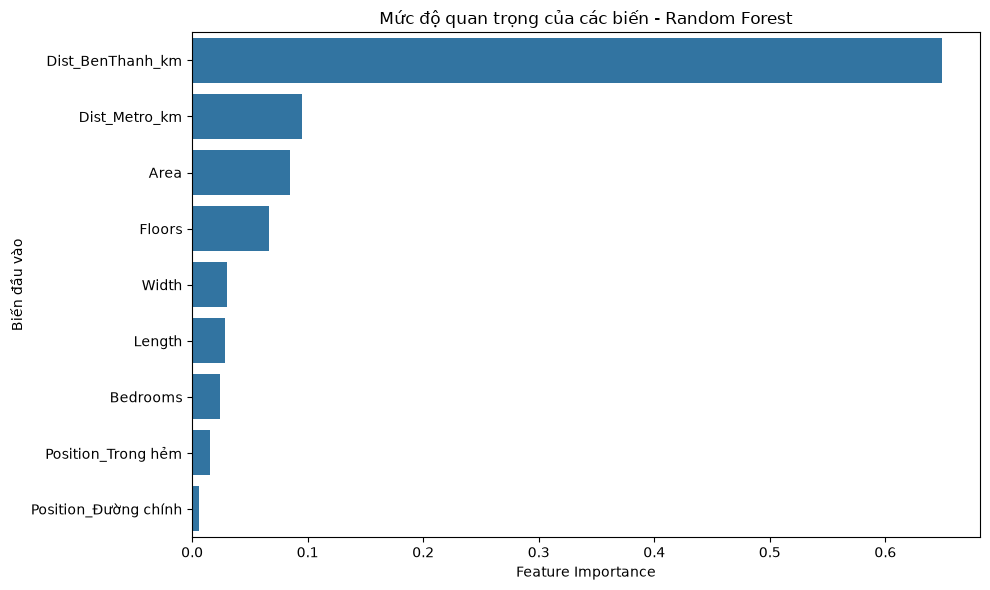

In [29]:
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

display(importance_df)

importance_df.to_csv(
    "../report/random_forest_muc_do_quan_trong_cua_bien.csv",
    index=False,
    encoding="utf-8-sig"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Mức độ quan trọng của các biến - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Biến đầu vào")

plt.tight_layout()

plt.savefig(
    "../report/random_forest_muc_do_quan_trong_cua_bien.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

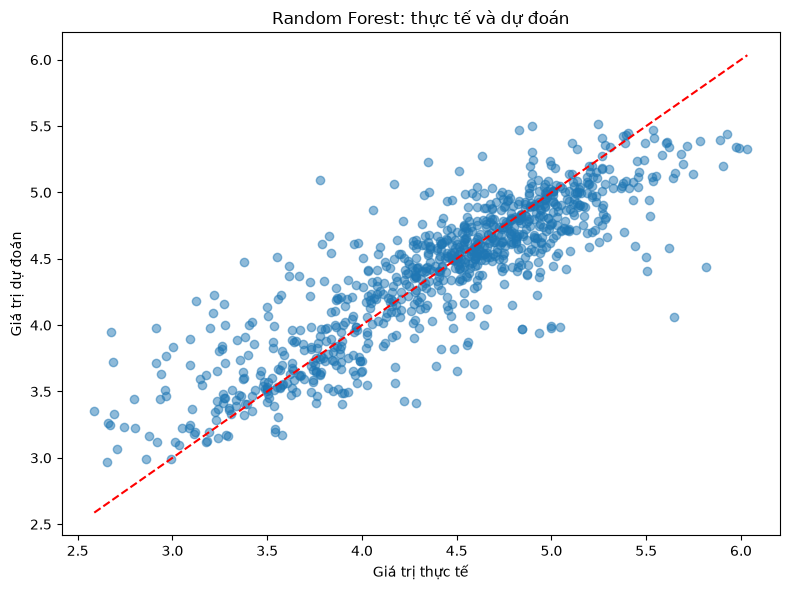

In [30]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_rf,
    alpha=0.5
)

min_value = min(y_test.min(), y_pred_rf.min())
max_value = max(y_test.max(), y_pred_rf.max())


plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    color="red"
)

plt.xlabel("Giá trị thực tế")
plt.ylabel("Giá trị dự đoán")

plt.title("Random Forest: thực tế và dự đoán")

plt.tight_layout()

plt.savefig(
    "../report/random_forest_thuc_te_va_du_doan.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
rf_predictions = pd.DataFrame({
    "Actual": np.asarray(y_test),
    "Predicted": np.asarray(y_pred_rf)
})

rf_predictions.to_csv(
    "../report/rf_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu kết quả dự đoán Random Forest.")

Đã lưu kết quả dự đoán Random Forest.
